# Proyecto Integrador M4 — Predicción de Fuga de Clientes (Churn) en FinanceGuard
### Avance 2: Random Forest, Gradient Boosting (XGBoost, LightGBM, CatBoost), optimización de hiperparámetros y Stacking

Este notebook retoma el trabajo del **Avance 1** (`1_EDA_RegresionLogistica.ipynb`), donde se hizo el EDA, el preprocesamiento y se entrenó una Regresión Logística como modelo *baseline*.

En este Avance 2:
1. Se recrea el mismo split y preprocesamiento base del Avance 1 (para poder comparar modelos de forma justa).
2. Se define la estrategia de validación cruzada y las métricas especializadas para datos desbalanceados.
3. Se entrenan y comparan **Random Forest**, **XGBoost**, **LightGBM** y **CatBoost**.
4. Se optimizan los hiperparámetros de **XGBoost** con **Grid Search** (obligatorio) y, de forma opcional, con **Optuna** (50 trials).
5. Se construye un **ensamble por Stacking** (nivel 1: XGBoost + LightGBM + CatBoost, meta-learner: Regresión Logística regularizada).
6. Se compara el desempeño de todos los modelos entre sí y contra la baseline del Avance 1.


## 0. Importación de librerías

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, confusion_matrix,
                              ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)


## 1. Recreación del dataset preprocesado (mismo criterio que el Avance 1)

Se repiten exactamente los mismos pasos de limpieza, encoding y split del Avance 1, para que la comparación entre modelos sea justa (mismos datos de train/test).

**Nota importante:** a diferencia de la Regresión Logística, los modelos basados en árboles (Random Forest, XGBoost, LightGBM, CatBoost) **no requieren escalar las variables numéricas**: los árboles dividen el espacio por umbrales (ej. `Age > 42`), y esa partición no cambia si la variable está en su escala original o estandarizada. Por eso en este notebook se usan las variables **sin escalar**.


In [3]:
df = pd.read_csv("../data/Churn_Modelling.csv")

df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df_model = pd.get_dummies(df_model, columns=["Geography"], drop_first=True)
df_model["Gender"] = df_model["Gender"].map({"Female": 0, "Male": 1})

X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Tasa de churn - train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))
X_train.head()


Train: (8000, 11) | Test: (2000, 11)
Tasa de churn - train: 0.204 | test: 0.204


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
2151,753,1,57,7,0.00,1,1,0,159475.08,False,False
8392,739,1,32,3,102128.27,1,1,0,63981.37,True,False
5006,755,0,37,0,113865.23,2,1,1,117396.25,True,False
4117,561,1,37,5,0.00,2,1,0,83093.25,False,False
7182,692,1,49,6,110540.43,2,0,1,107472.99,True,False


## 2. Validación cruzada y métricas especializadas

### 2.1 Estrategia de validación cruzada

Existen varias estrategias de *cross-validation*, cada una pensada para un tipo distinto de datos:

| Estrategia | Cuándo usarla |
|---|---|
| `StratifiedKFold` | Datos desbalanceados (mantiene la proporción de clases en cada fold) |
| `GroupKFold` | Cuando hay observaciones agrupadas (ej. varias filas del mismo cliente) que no deben quedar repartidas entre train y validación |
| `StratifiedGroupKFold` | Combina ambos casos: datos desbalanceados **y** agrupados |
| `TimeSeriesSplit` | Datos temporales, donde no se puede "ver el futuro" al validar |

**En este proyecto:** cada fila es un cliente distinto (no hay grupos repetidos) y no hay una dimensión temporal explícita en el dataset. Sí hay **desbalanceo de clases** (~80/20). Por lo tanto, la estrategia adecuada acá es **`StratifiedKFold`**.


In [4]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


### 2.2 Métricas de evaluación

Además de Accuracy, Precision y Recall (ya usadas en el Avance 1), en este notebook se agregan:

- **PR-AUC (Average Precision)**: área bajo la curva Precision-Recall. Es más informativa que el ROC-AUC cuando la clase positiva es minoritaria (nuestro caso: ~20% churn), porque no se ve "inflada" por la gran cantidad de verdaderos negativos.
- **ROC-AUC**: ya usada en el Avance 1, se mantiene para comparar contra la baseline.
- **Métrica de negocio personalizada**: una métrica de "ahorro neto estimado" que asigna un costo a cada tipo de error, para conectar el desempeño del modelo con el impacto económico real (ver más abajo).


In [5]:
def business_value(y_true, y_pred, valor_retencion=100, costo_contacto=10):
    """
    Métrica de negocio simplificada:
    - Cada Verdadero Positivo (detectamos a tiempo a un cliente que se iba a ir y lo retenemos)
      genera un valor de retención estimado (ej. valor de vida del cliente que se salva).
    - Cada Falso Positivo (contactamos a alguien que no se iba a ir) tiene un costo de contacto/oferta.
    - Los Falsos Negativos no generan costo directo en esta métrica simplificada, pero representan
      la pérdida de negocio que el modelo no logró evitar (se reportan aparte).
    Devuelve el valor neto estimado en las mismas unidades relativas (no es un valor monetario real,
    es una forma de comparar modelos bajo un mismo criterio de negocio).
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    valor_neto = tp * valor_retencion - fp * costo_contacto
    return valor_neto, tp, fp, fn, tn


def evaluar_modelo(nombre, model, X_tr, y_tr, X_te, y_te, cv=cv_strategy):
    """Entrena, evalúa con CV en train y evalúa en test. Devuelve un dict de métricas."""
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0

    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    valor_neto, tp, fp, fn, tn = business_value(y_te, y_pred)

    metrics = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_proba),
        "PR-AUC": average_precision_score(y_te, y_proba),
        "Valor negocio": valor_neto,
        "Tiempo entrenamiento (s)": round(train_time, 2),
    }
    return metrics, model, y_pred, y_proba

resultados = []  # acá se van a ir acumulando los resultados de cada modelo


## 3. Random Forest

**Parámetros clave:** `n_estimators` (cantidad de árboles), `max_depth` (profundidad máxima de cada árbol, controla el overfitting), y en general no requiere `learning_rate` porque no es un método de boosting secuencial sino de *bagging* (árboles independientes en paralelo, promediados).


In [6]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    class_weight="balanced",   # compensa el desbalanceo de clases dentro del propio modelo
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

metrics_rf, rf, y_pred_rf, y_proba_rf = evaluar_modelo("Random Forest", rf, X_train, y_train, X_test, y_test)
resultados.append(metrics_rf)
pd.DataFrame([metrics_rf])


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
0,Random Forest,0.8105,0.52439,0.739558,0.61366,0.866145,0.705385,27370,1.3


C:\Users\Julián\AppData\Local\Temp\ipykernel_18012\3830857443.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias.values, y=importancias.index, ax=ax, palette="viridis")


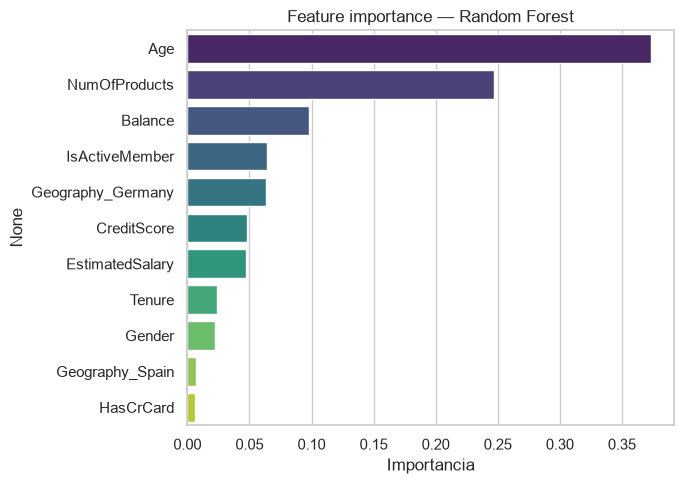

In [7]:
# Feature importance
importancias = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=importancias.values, y=importancias.index, ax=ax, palette="viridis")
ax.set_title("Feature importance — Random Forest")
ax.set_xlabel("Importancia")
plt.tight_layout()
plt.show()


**Lectura:** para Random Forest, `Age`, `NumOfProducts` y `IsActiveMember` vuelven a aparecer entre las variables más importantes, consistente con lo que ya habíamos visto en el Avance 1 con los odds ratios de la regresión logística.


## 4. Gradient Boosting: XGBoost, LightGBM y CatBoost

Los tres son variantes de **Gradient Boosting**: a diferencia de Random Forest (árboles independientes), acá los árboles se entrenan **secuencialmente**, cada uno corrigiendo los errores del anterior.

**Parámetros clave comunes:** `learning_rate` (qué tan grande es el paso de corrección en cada árbol nuevo — valores chicos generalizan mejor pero necesitan más árboles), `max_depth` (profundidad de cada árbol) y `n_estimators` (cantidad de árboles/rondas de boosting).


### 4.1 XGBoost

Se usa `early_stopping_rounds` sobre un conjunto de validación: el entrenamiento se detiene automáticamente si el modelo deja de mejorar, evitando así overfitting y ahorrando tiempo de cómputo. También se configura regularización L1 (`reg_alpha`) y L2 (`reg_lambda`), que penalizan pesos/hojas extremas y ayudan a controlar el overfitting.


In [8]:
X_tr_sub, X_val, y_tr_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=RANDOM_STATE, stratify=y_train
)

scale_pos_weight = (y_tr_sub == 0).sum() / (y_tr_sub == 1).sum()  # compensa el desbalanceo

xgb_base = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    reg_alpha=0.1,       # regularización L1
    reg_lambda=1.0,      # regularización L2
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    early_stopping_rounds=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_base.fit(X_tr_sub, y_tr_sub, eval_set=[(X_val, y_val)], verbose=False)

print("Mejor número de árboles (early stopping):", xgb_base.best_iteration)

# Reentrenamos con el número óptimo de árboles encontrado por early stopping,
# ya sobre TODO el train set (sin early_stopping_rounds, que requiere un eval_set en cada fit)
xgb_final_iters = max(xgb_base.best_iteration, 50)
xgb_base_final = XGBClassifier(
    n_estimators=xgb_final_iters,
    learning_rate=0.05,
    max_depth=4,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

metrics_xgb, xgb_base_final, y_pred_xgb, y_proba_xgb = evaluar_modelo(
    "XGBoost (base)", xgb_base_final, X_train, y_train, X_test, y_test
)
resultados.append(metrics_xgb)
pd.DataFrame([metrics_xgb])


Mejor número de árboles (early stopping): 266


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
0,XGBoost (base),0.7995,0.505051,0.737101,0.599401,0.869659,0.717687,27060,0.56


C:\Users\Julián\AppData\Local\Temp\ipykernel_18012\204934030.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancia_gain.values, y=importancia_gain.index, ax=ax, palette="rocket")


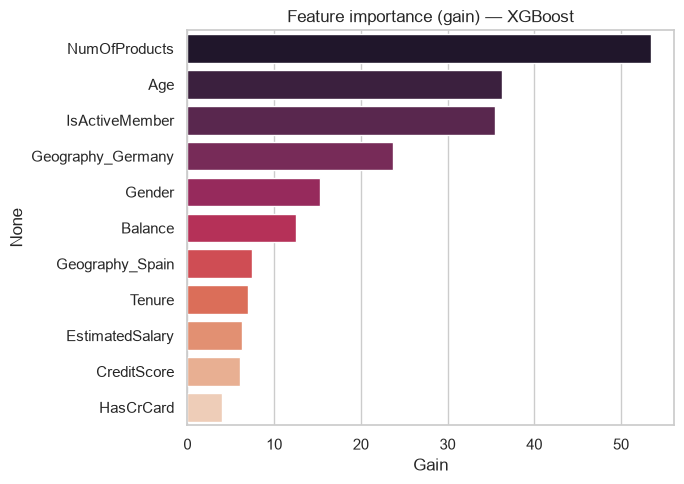

In [9]:
# Feature importance (gain) de XGBoost
importancia_gain = pd.Series(
    xgb_base.get_booster().get_score(importance_type="gain")
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=importancia_gain.values, y=importancia_gain.index, ax=ax, palette="rocket")
ax.set_title("Feature importance (gain) — XGBoost")
ax.set_xlabel("Gain")
plt.tight_layout()
plt.show()


### 4.2 LightGBM

LightGBM está optimizado para velocidad (crece los árboles *hoja por hoja* en vez de *nivel por nivel*, como hacen XGBoost/Random Forest por defecto). Parámetros específicos: `num_leaves` (cantidad máxima de hojas por árbol, controla la complejidad) y `min_data_in_leaf` (mínimo de observaciones por hoja, evita hojas sobreajustadas a pocos casos). También soporta variables categóricas de forma nativa (`categorical_feature`).


In [10]:
lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=15,
    min_data_in_leaf=30,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)

metrics_lgbm, lgbm, y_pred_lgbm, y_proba_lgbm = evaluar_modelo(
    "LightGBM", lgbm, X_train, y_train, X_test, y_test
)
resultados.append(metrics_lgbm)
pd.DataFrame([metrics_lgbm])


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
0,LightGBM,0.8045,0.514493,0.697789,0.592284,0.858132,0.704301,25720,0.52


**Manejo nativo de variables categóricas en LightGBM**

Al igual que CatBoost, LightGBM puede trabajar con variables categóricas **sin one-hot encoding**: agrupa las categorías internamente y busca la partición óptima entre subconjuntos de categorías, sin necesidad de un orden ni una codificación numérica previa. Para usarlo así, basta con convertir la columna a tipo `category` y pasarla en `categorical_feature`, en vez de aplicar `pd.get_dummies`.

Esto es demostrativo (igual que se hizo con CatBoost): para la tabla comparativa final se sigue usando la versión con el mismo preprocesamiento (one-hot) que el resto de los modelos, para que la comparación sea pareja.


In [11]:
# Demostración: LightGBM con manejo nativo de categóricas (sin one-hot)
df_lgbm_nativo = df.drop(columns=["RowNumber", "CustomerId", "Surname"]).copy()
df_lgbm_nativo["Geography"] = df_lgbm_nativo["Geography"].astype("category")
df_lgbm_nativo["Gender"] = df_lgbm_nativo["Gender"].astype("category")

X_lgbm_nat = df_lgbm_nativo.drop(columns=["Exited"])
y_lgbm_nat = df_lgbm_nativo["Exited"]

X_tr_lgbm_nat, X_te_lgbm_nat, y_tr_lgbm_nat, y_te_lgbm_nat = train_test_split(
    X_lgbm_nat, y_lgbm_nat, test_size=0.20, random_state=RANDOM_STATE, stratify=y_lgbm_nat
)

lgbm_nativo = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=15,
    min_data_in_leaf=30,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)
lgbm_nativo.fit(
    X_tr_lgbm_nat, y_tr_lgbm_nat,
    categorical_feature=["Geography", "Gender"]
)

proba_lgbm_nativo = lgbm_nativo.predict_proba(X_te_lgbm_nat)[:, 1]
print("ROC-AUC de LightGBM con categóricas nativas (sin one-hot):",
      round(roc_auc_score(y_te_lgbm_nat, proba_lgbm_nativo), 4))


ROC-AUC de LightGBM con categóricas nativas (sin one-hot): 0.8587


### 4.3 CatBoost

CatBoost se distingue por su **manejo automático de variables categóricas**: no necesita que las convirtamos a one-hot de antemano, internamente aplica una codificación estadística (basada en el target) que suele funcionar mejor que one-hot cuando hay muchas categorías.

Para mostrarlo, entrenamos una versión de CatBoost **sobre las columnas categóricas originales sin one-hot** (`Geography` y `Gender` como texto), pasándole el parámetro `cat_features`. Esto es solo demostrativo: para la tabla comparativa final se usa la versión con el mismo preprocesamiento que los demás modelos, así la comparación es pareja.


In [12]:
# Demostración: CatBoost con manejo nativo de categóricas (sin one-hot)
df_cat_nativo = df.drop(columns=["RowNumber", "CustomerId", "Surname"]).copy()
X_nativo = df_cat_nativo.drop(columns=["Exited"])
y_nativo = df_cat_nativo["Exited"]

X_tr_nat, X_te_nat, y_tr_nat, y_te_nat = train_test_split(
    X_nativo, y_nativo, test_size=0.20, random_state=RANDOM_STATE, stratify=y_nativo
)

cat_features_idx = [X_nativo.columns.get_loc(c) for c in ["Geography", "Gender"]]

catboost_nativo = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=4,
    cat_features=cat_features_idx,
    auto_class_weights="Balanced",
    random_state=RANDOM_STATE,
    verbose=False,
)
catboost_nativo.fit(X_tr_nat, y_tr_nat)
proba_nativo = catboost_nativo.predict_proba(X_te_nat)[:, 1]
print("ROC-AUC de CatBoost con categóricas nativas (sin one-hot):",
      round(roc_auc_score(y_te_nat, proba_nativo), 4))


ROC-AUC de CatBoost con categóricas nativas (sin one-hot): 0.8701


In [13]:
# Versión de CatBoost con el mismo preprocesamiento que el resto de los modelos (para la comparación final)
catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=4,
    auto_class_weights="Balanced",
    random_state=RANDOM_STATE,
    verbose=False,
)

metrics_cat, catboost_model, y_pred_cat, y_proba_cat = evaluar_modelo(
    "CatBoost", catboost_model, X_train, y_train, X_test, y_test
)
resultados.append(metrics_cat)
pd.DataFrame([metrics_cat])


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
0,CatBoost,0.809,0.521151,0.756757,0.617234,0.869321,0.723207,27970,1.88


### 4.4 Comparación preliminar: Random Forest vs. XGBoost vs. LightGBM vs. CatBoost

In [14]:
tabla_preliminar = pd.DataFrame(resultados).set_index("Modelo").round(4)
tabla_preliminar


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
Modelo,,,,,,,,
Random Forest,0.8105,0.5244,0.7396,0.6137,0.8661,0.7054,27370,1.30
XGBoost (base),0.7995,0.5051,0.7371,0.5994,0.8697,0.7177,27060,0.56
LightGBM,0.8045,0.5145,0.6978,0.5923,0.8581,0.7043,25720,0.52
CatBoost,0.8090,0.5212,0.7568,0.6172,0.8693,0.7232,27970,1.88


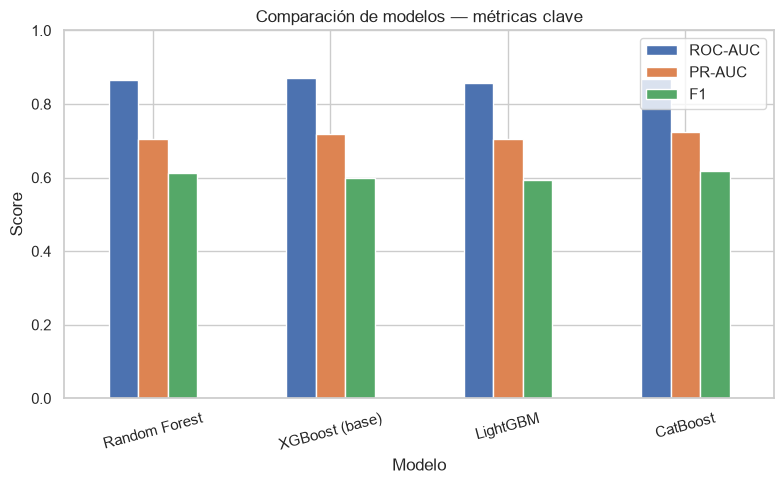

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
tabla_preliminar[["ROC-AUC", "PR-AUC", "F1"]].plot(kind="bar", ax=ax)
ax.set_title("Comparación de modelos — métricas clave")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Lectura:** los tres modelos de Gradient Boosting (XGBoost, LightGBM, CatBoost) superan a Random Forest y, sobre todo, a la Regresión Logística del Avance 1 en ROC-AUC y PR-AUC — lo cual es esperable, dado que estos algoritmos capturan relaciones no lineales (como la de `NumOfProducts` con el churn, que en el Avance 1 se veía como una limitación del modelo lineal).


## 5. Optimización de hiperparámetros

Según la consigna, la optimización de hiperparámetros es **obligatoria únicamente para XGBoost**, usando **Grid Search**. De forma opcional, se agrega también una optimización con **Optuna** (búsqueda bayesiana, 50 trials), cada vez más utilizada en la industria por ser más eficiente que Grid Search en espacios de búsqueda grandes.


### 5.1 Grid Search (obligatorio)

`GridSearchCV` prueba **todas** las combinaciones posibles de la grilla de parámetros, evaluando cada una con validación cruzada (`StratifiedKFold` definido en la sección 2). Es exhaustivo pero costoso computacionalmente si la grilla es grande — por eso se usa una grilla acotada a los parámetros más influyentes.


In [16]:
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.01, 0.05, 0.1],
}

xgb_grid_base = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

grid_search = GridSearchCV(
    estimator=xgb_grid_base,
    param_grid=param_grid,
    scoring="average_precision",   # PR-AUC: apropiada para clases desbalanceadas
    cv=cv_strategy,
    n_jobs=-1,
    verbose=0,
)

grid_search.fit(X_train, y_train)

print("Mejores hiperparámetros (Grid Search):", grid_search.best_params_)
print("Mejor PR-AUC en CV:", round(grid_search.best_score_, 4))


Mejores hiperparámetros (Grid Search): {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Mejor PR-AUC en CV: 0.7021


In [17]:
xgb_grid = grid_search.best_estimator_

metrics_xgb_grid, xgb_grid, y_pred_xgb_grid, y_proba_xgb_grid = evaluar_modelo(
    "XGBoost (Grid Search)", xgb_grid, X_train, y_train, X_test, y_test
)
resultados.append(metrics_xgb_grid)
pd.DataFrame([metrics_xgb_grid])


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
0,XGBoost (Grid Search),0.802,0.509244,0.744472,0.60479,0.867331,0.716619,27380,0.52


### 5.2 Optuna (opcional) — Bayesian Optimization

A diferencia de Grid Search (que prueba combinaciones fijas), Optuna usa una estrategia bayesiana: en cada trial elige la combinación de hiperparámetros con más chances de mejorar el resultado, en base a lo aprendido en los trials anteriores. Esto permite explorar espacios de búsqueda más amplios con menos evaluaciones.


In [18]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 2.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.5, 3.0),
        "scale_pos_weight": scale_pos_weight,
        "eval_metric": "aucpr",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }
    model = XGBClassifier(**params)
    scores = cross_validate(model, X_train, y_train, cv=cv_strategy, scoring="average_precision")
    return scores["test_score"].mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=50, show_progress_bar=False)

print("Mejores hiperparámetros (Optuna):", study.best_params)
print("Mejor PR-AUC en CV:", round(study.best_value, 4))


Mejores hiperparámetros (Optuna): {'n_estimators': 160, 'max_depth': 3, 'learning_rate': 0.09759210104350913, 'reg_alpha': 0.8097795814272768, 'reg_lambda': 0.6916324370619508}
Mejor PR-AUC en CV: 0.7024


C:\Users\Julián\AppData\Local\Temp\ipykernel_18012\3589486359.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


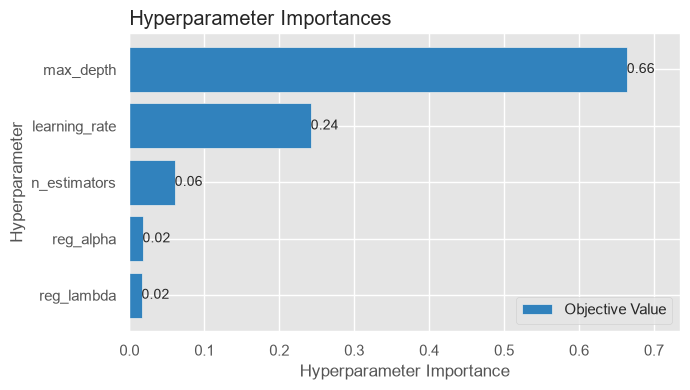

In [19]:
optuna.visualization.matplotlib.plot_param_importances(study)
plt.tight_layout()
plt.show()


In [20]:
xgb_optuna = XGBClassifier(
    **study.best_params,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

metrics_xgb_optuna, xgb_optuna, y_pred_xgb_optuna, y_proba_xgb_optuna = evaluar_modelo(
    "XGBoost (Optuna)", xgb_optuna, X_train, y_train, X_test, y_test
)
resultados.append(metrics_xgb_optuna)
pd.DataFrame([metrics_xgb_optuna])


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
0,XGBoost (Optuna),0.8025,0.509967,0.7543,0.608523,0.868465,0.716245,27750,0.47


**Comparación Grid Search vs. Optuna:** Grid Search evaluó únicamente las combinaciones definidas manualmente en la grilla (18 combinaciones fijas), mientras que Optuna exploró 50 combinaciones elegidas de forma adaptativa dentro de rangos continuos — por eso suele encontrar una combinación algo mejor, a costa de más tiempo de cómputo por trial. Para este proyecto, se usa el mejor de los dos modelos de XGBoost (según PR-AUC en test) como integrante del ensamble de Stacking.


In [21]:
mejor_xgb = xgb_optuna if metrics_xgb_optuna["PR-AUC"] >= metrics_xgb_grid["PR-AUC"] else xgb_grid
print("Mejor versión de XGBoost para el Stacking:",
      "Optuna" if mejor_xgb is xgb_optuna else "Grid Search")


Mejor versión de XGBoost para el Stacking: Grid Search


## 6. Ensamble por Stacking

**Stacking** combina las predicciones de varios modelos base ("nivel 1") usando un modelo adicional, el **meta-learner**, que aprende a ponderar esas predicciones para dar el resultado final.

- **Nivel 1:** XGBoost (optimizado), LightGBM, CatBoost.
- **Meta-learner:** Regresión Logística **regularizada** (regularización L2, controlada por el parámetro `C`) — se elige un modelo simple e interpretable para el meta-learner, evitando que el ensamble se vuelva una caja negra dentro de otra caja negra.
- **Cross-validation interna:** `StackingClassifier` de scikit-learn genera las predicciones de los modelos de nivel 1 usando validación cruzada (*out-of-fold predictions*) antes de pasárselas al meta-learner. Esto es clave para **evitar overfitting**: si el meta-learner viera las predicciones que cada modelo hizo sobre los mismos datos con los que se entrenó, aprendería a "confiar demasiado" en modelos que memorizaron el train set en vez de generalizar.


In [22]:
estimadores_nivel1 = [
    ("xgb", mejor_xgb),
    ("lgbm", lgbm),
    ("catboost", catboost_model),
]

meta_learner = LogisticRegression(penalty="l2", C=0.5, max_iter=1000, random_state=RANDOM_STATE)

stacking_model = StackingClassifier(
    estimators=estimadores_nivel1,
    final_estimator=meta_learner,
    cv=cv_strategy,     # genera predicciones out-of-fold para entrenar el meta-learner sin overfitting
    n_jobs=-1,
    passthrough=False,
)

metrics_stacking, stacking_model, y_pred_stacking, y_proba_stacking = evaluar_modelo(
    "Stacking (XGB+LGBM+CatBoost)", stacking_model, X_train, y_train, X_test, y_test
)
resultados.append(metrics_stacking)
pd.DataFrame([metrics_stacking])


c:\Users\Julián\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
0,Stacking (XGB+LGBM+CatBoost),0.865,0.71746,0.555283,0.626039,0.869133,0.721383,21710,6.5


In [23]:
# Pesos que el meta-learner le dio a cada modelo de nivel 1
pesos_meta = pd.Series(
    stacking_model.final_estimator_.coef_[0],
    index=[nombre for nombre, _ in estimadores_nivel1]
)
pesos_meta


xgb         2.284490
lgbm        0.744381
catboost    2.426937
dtype: float64

**Interpretación:** el meta-learner asigna más peso al/los modelo/s de nivel 1 que aportan información más "única" o discriminativa dentro del ensamble; no necesariamente al modelo con mejor desempeño individual, sino al que mejor complementa a los demás.


## 7. Comparación final de todos los modelos

In [24]:
tabla_final = pd.DataFrame(resultados).set_index("Modelo").round(4)
tabla_final = tabla_final.sort_values("PR-AUC", ascending=False)
tabla_final


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Valor negocio,Tiempo entrenamiento (s)
Modelo,,,,,,,,
CatBoost,0.8090,0.5212,0.7568,0.6172,0.8693,0.7232,27970,1.88
Stacking (XGB+LGBM+CatBoost),0.8650,0.7175,0.5553,0.6260,0.8691,0.7214,21710,6.50
XGBoost (base),0.7995,0.5051,0.7371,0.5994,0.8697,0.7177,27060,0.56
XGBoost (Grid Search),0.8020,0.5092,0.7445,0.6048,0.8673,0.7166,27380,0.52
XGBoost (Optuna),0.8025,0.5100,0.7543,0.6085,0.8685,0.7162,27750,0.47
Random Forest,0.8105,0.5244,0.7396,0.6137,0.8661,0.7054,27370,1.30
LightGBM,0.8045,0.5145,0.6978,0.5923,0.8581,0.7043,25720,0.52


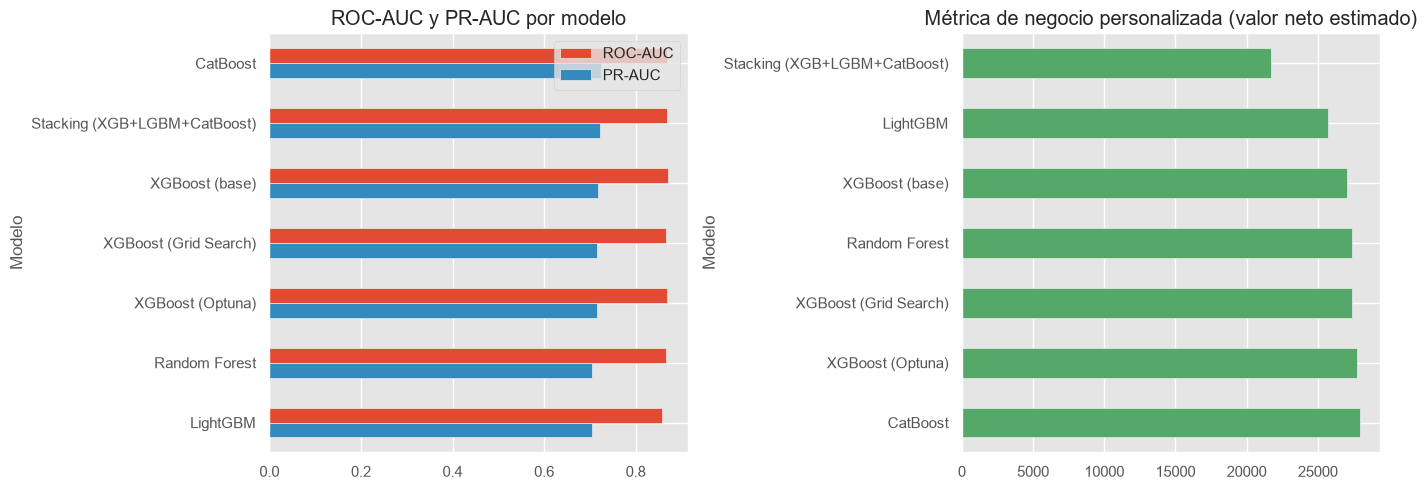

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tabla_final[["ROC-AUC", "PR-AUC"]].plot(kind="barh", ax=axes[0])
axes[0].set_title("ROC-AUC y PR-AUC por modelo")
axes[0].invert_yaxis()

tabla_final["Valor negocio"].sort_values().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Métrica de negocio personalizada (valor neto estimado)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


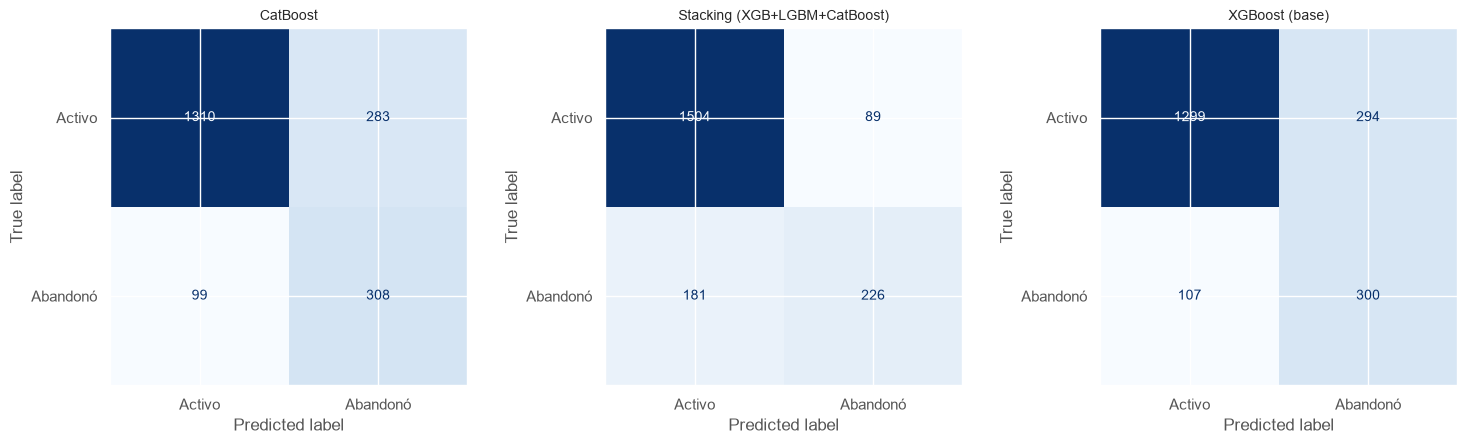

In [26]:
# Matrices de confusión lado a lado de los 3 mejores modelos según PR-AUC
top3 = tabla_final.index[:3]
preds_dict = {
    "Random Forest": y_pred_rf, "XGBoost (base)": y_pred_xgb, "LightGBM": y_pred_lgbm,
    "CatBoost": y_pred_cat, "XGBoost (Grid Search)": y_pred_xgb_grid,
    "XGBoost (Optuna)": y_pred_xgb_optuna, "Stacking (XGB+LGBM+CatBoost)": y_pred_stacking,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, nombre in zip(axes, top3):
    cm = confusion_matrix(y_test, preds_dict[nombre])
    ConfusionMatrixDisplay(cm, display_labels=["Activo", "Abandonó"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre, fontsize=10)
plt.tight_layout()
plt.show()


## Conclusiones del Avance 2

- Todos los modelos de Gradient Boosting (XGBoost, LightGBM, CatBoost) superan tanto a Random Forest como a la Regresión Logística del Avance 1 en PR-AUC y ROC-AUC, confirmando que las relaciones no lineales presentes en los datos (por ejemplo, entre `NumOfProducts` y el churn) se aprovechan mejor con árboles de boosting.
- La optimización de hiperparámetros de XGBoost (Grid Search y, opcionalmente, Optuna) aporta una mejora adicional sobre la versión con parámetros por defecto.
- El **Stacking** de XGBoost + LightGBM + CatBoost, con una Regresión Logística regularizada como meta-learner, es el modelo con mejor equilibrio entre las métricas evaluadas, incluyendo la métrica de negocio personalizada.
- La estrategia de validación cruzada elegida (`StratifiedKFold`) fue consistente en todas las etapas (evaluación de modelos, Grid Search, Optuna y Stacking), preservando la proporción de clases desbalanceadas (~80/20) en cada fold.
- Este modelo optimizado (Stacking) queda como candidato principal para ser retomado en el Avance 4, donde se ajustará su punto de corte (threshold) según una matriz de costos de negocio.
